In [6]:
from pathlib import Path
import fitz  # PyMuPDF
import pandas as pd
from pathlib import Path
import fitz  # PyMuPDF
import pandas as pd
import json

In [3]:
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw"
PROCESSED = ROOT / "data" / "processed"
PROCESSED.mkdir(parents=True, exist_ok=True)

In [4]:
BANKS = {
    "RBC": "Royal Bank of Canada",
    "TD": "Toronto-Dominion Bank",
    "BMO": "Bank of Montreal",
    "BNS": "Bank of Nova Scotia",
    "CIBC": "Canadian Imperial Bank of Commerce",
}


In [ ]:
rows = []
for pdf in sorted(RAW.glob("*.pdf")):
    parts = pdf.stem.split("_")
    doc = fitz.open(pdf)
    rows.append({
        "bank_code": parts[0],
        "bank": BANKS[parts[0]],
        "document_type": "Annual Report",
        "fiscal_year": int(parts[3].replace("FY", "")),
        "file": pdf.name,
        "size_mb": round(pdf.stat().st_size / 1e6, 1),
        "pages": doc.page_count,
    })
    doc.close()

inventory = pd.DataFrame(rows)
print(inventory.to_string(index=False))

bank_code                               bank document_type  fiscal_year                          file  size_mb  pages
      BMO                   Bank of Montreal Annual Report         2024  BMO_annual_report_FY2024.pdf      2.3    211
      BMO                   Bank of Montreal Annual Report         2025  BMO_annual_report_FY2025.pdf      2.9    207
      BNS                Bank of Nova Scotia Annual Report         2024  BNS_annual_report_FY2024.pdf      6.7    236
      BNS                Bank of Nova Scotia Annual Report         2025  BNS_annual_report_FY2025.pdf     12.9    236
     CIBC Canadian Imperial Bank of Commerce Annual Report         2024 CIBC_annual_report_FY2024.pdf     14.7    211
     CIBC Canadian Imperial Bank of Commerce Annual Report         2025 CIBC_annual_report_FY2025.pdf     13.1    200
      RBC               Royal Bank of Canada Annual Report         2024  RBC_annual_report_FY2024.pdf      6.5    250
      RBC               Royal Bank of Canada Annual Repo

In [19]:
pages = []
for _, f in inventory.iterrows():
    with fitz.open(RAW / f.file) as doc:
        for i, page in enumerate(doc):
            pages.append({**f.drop("pages").to_dict(), "page": i + 1, "text": page.get_text("text", sort=True)})
pages_df = pd.DataFrame(pages)
print(f"{len(pages_df)} pages extraites")
pages_df[["file", "page", "text"]].sample(3, random_state=1)

2262 pages extraites


,file,page,text
1196,CIBC_annual_report_FY2025.pdf,96,Management’s discussion and analysis\n\n\n ...
1228,CIBC_annual_report_FY2025.pdf,128,Consolidated financial statements\n\n\n Ass...
1488,RBC_annual_report_FY2024.pdf,188,Note 5 Loans and allowance for credit losse...


In [20]:
# Retirer en-têtes, pieds de page et numéros de page
import re
from collections import Counter

def norm(line):
    # remplace les chiffres : "Annual Report 54" et "Annual Report 55" deviennent la même ligne
    return re.sub(r"\d+", "#", line.strip())[:90]

def edge_idx(lines):
    # indices des 2 premières et 2 dernières lignes non vides de la page
    idx = [i for i, l in enumerate(lines) if l.strip()]
    return idx[:2] + idx[-2:]

clean_text = {}
removed = {}
for file, g in pages_df.groupby("file", sort=False):
    # 1) lignes qui reviennent en haut/bas sur plus de 15 % des pages = en-têtes/pieds de page
    counts = Counter()
    for t in g.text:
        lines = t.splitlines()
        for i in edge_idx(lines):
            counts[norm(lines[i])] += 1
    repeated = {k for k, c in counts.items() if c > 0.15 * len(g) and k.strip("# ")}

    # 2) on les retire, ainsi que les numéros de page seuls
    for idx, t in g.text.items():
        lines = t.splitlines()
        edge = set(edge_idx(lines))
        kept, gone = [], []
        for i, l in enumerate(lines):
            s = l.strip()
            if i in edge and len(s) < 100 and (norm(s) in repeated or re.fullmatch(r"\d{1,3}", s)):
                gone.append(s)
            else:
                kept.append(l)
        clean_text[idx] = "\n".join(kept).strip()
        removed[idx] = gone

pages_df["clean_text"] = pd.Series(clean_text)
pages_df["removed"] = pd.Series(removed)

# Contrôle 1 : combien de lignes retirées par fichier
print(pages_df.groupby("file").removed.apply(lambda s: sum(len(x) for x in s)))

# Contrôle 2 : lignes retirées et début de page nettoyée (BMO FY2025, page 100)
i = pages_df[(pages_df.file == "BMO_annual_report_FY2025.pdf") & (pages_df.page == 100)].index[0]
print("\n--- Lignes retirées ---")
print(pages_df.at[i, "removed"])
print("\n--- Début de la page, après nettoyage ---")
print(pages_df.at[i, "clean_text"][:400])

file
BMO_annual_report_FY2024.pdf     326
BMO_annual_report_FY2025.pdf     319
BNS_annual_report_FY2024.pdf     334
BNS_annual_report_FY2025.pdf     334
CIBC_annual_report_FY2024.pdf    376
CIBC_annual_report_FY2025.pdf    360
RBC_annual_report_FY2024.pdf     199
RBC_annual_report_FY2025.pdf     190
TD_annual_report_FY2024.pdf      174
TD_annual_report_FY2025.pdf      176
Name: removed, dtype: int64

--- Lignes retirées ---
['MANAGEMENT’S DISCUSSION AND ANALYSIS', '98 BMO Financial Group 208th Annual Report 2025']

--- Début de la page, après nettoyage ---
Operational Non-Financial Risk


          Operational Non-Financial Risk encompasses a wide range of non-financial risks, including those related to business change, customer trust,
           reputation and data, all of which can result in financial loss. These losses can stem from inadequate or failed internal processes or systems,
        human error or misconduct, and external events that may


In [24]:
# Repérer les pages de table des matières
def looks_like_toc(page, text):
    if page > 8:
        return False
    lines = [l.strip() for l in text.splitlines() if l.strip()]
    head = text[:300].lower()
    if re.search(r"table of contents|what.s inside|^\s*contents\b", head):
        return True
    num_start = sum(bool(re.match(r"^\d{1,3}\s+\S", l)) for l in lines)
    num_end = sum(bool(re.search(r"\s\d{1,3}$", l)) for l in lines)
    return (num_start + num_end) >= 10

pages_df["is_toc"] = [looks_like_toc(p, t) for p, t in zip(pages_df.page, pages_df.clean_text)]

print(pages_df.groupby("file").is_toc.sum())
print()
for _, r in pages_df[pages_df.is_toc].iterrows():
    print(f"{r.file} p.{r.page}: {' '.join(r.clean_text.split())[:90]!r}")

file
BMO_annual_report_FY2024.pdf     1
BMO_annual_report_FY2025.pdf     1
BNS_annual_report_FY2024.pdf     1
BNS_annual_report_FY2025.pdf     0
CIBC_annual_report_FY2024.pdf    0
CIBC_annual_report_FY2025.pdf    0
RBC_annual_report_FY2024.pdf     1
RBC_annual_report_FY2025.pdf     3
TD_annual_report_FY2024.pdf      1
TD_annual_report_FY2025.pdf      1
Name: is_toc, dtype: int64

BMO_annual_report_FY2024.pdf p.2: 'Business Review 1 Strategy 2 Chair’s Message &KLHI ([HFXWLYH 2IːFHUɉV 0HVVDJH 6 Financial '
BMO_annual_report_FY2025.pdf p.2: 'Bank of Montreal brands the organization’s member companies as BMO Financial Group. Note 2'
BNS_annual_report_FY2024.pdf p.3: 'What’s inside CEO’s message 1 CEO’s Message to shareholders to Shareholders Fellow shareho'
RBC_annual_report_FY2024.pdf p.3: 'Table of contents CEO Letter 6 Reports and Consolidated 141 Financial Statements Chair Let'
RBC_annual_report_FY2025.pdf p.1: 'Management’s Discussion and Analysis Management’s Discussion and Analysis 

In [25]:
# Correction manuelle + localiser les tables des matières ratées
pages_df.loc[(pages_df.file == "RBC_annual_report_FY2025.pdf") & pages_df.page.isin([1, 6, 7]), "is_toc"] = False

for f in ["BNS_annual_report_FY2025.pdf", "CIBC_annual_report_FY2024.pdf", "CIBC_annual_report_FY2025.pdf"]:
    print(f"\n=== {f} ===")
    for _, r in pages_df[(pages_df.file == f) & (pages_df.page <= 6)].iterrows():
        print(f"  p.{r.page}: {' '.join(r.clean_text.split())[:110]!r}")


=== BNS_annual_report_FY2025.pdf ===
  p.1: '2 0 2 5 A N N U A L R E P O R T'
  p.2: 'Scotiabank’s vision is Our Strategy to be our clients’ most trusted financial partner and deliver Launched at '
  p.3: "Scott Thomson President and Chief Executive Officer CEO's Message to Shareholders Fellow shareholders, What’s "
  p.4: 'We believe that a strong corporate culture is a strategic driver that fuels performance, strengthens alignment'
  p.5: 'As governments have explored new trade agreements In the Small Business segment, we are acquiring clients and '
  p.6: 'In Mexico, Scotiabank finished the year as the Earn Primary fourth-largest bank by loan portfolio, solidifying'

=== CIBC_annual_report_FY2024.pdf ===
  p.1: 'AnnualAnnual ReportReport 20242024'
  p.2: 'Who we are CIBC is a leading and well-diversified North American financial institution committed to creating e'
  p.3: '2024 performance at a glance Business mix Reported earnings Adjusted earnings (% reported revenue) per share(1

In [26]:
# BNS FY2025 p.3 marquée comme BNS FY2024, puis bilan
pages_df.loc[(pages_df.file == "BNS_annual_report_FY2025.pdf") & (pages_df.page == 3), "is_toc"] = True
print(f"Pages de table des matières marquées : {pages_df.is_toc.sum()} sur {len(pages_df)}")
print(pages_df[pages_df.is_toc][["file", "page"]].to_string(index=False))

Pages de table des matières marquées : 7 sur 2262
                        file  page
BMO_annual_report_FY2024.pdf     2
BMO_annual_report_FY2025.pdf     2
BNS_annual_report_FY2024.pdf     3
BNS_annual_report_FY2025.pdf     3
RBC_annual_report_FY2024.pdf     3
 TD_annual_report_FY2024.pdf     2
 TD_annual_report_FY2025.pdf     2


In [27]:
# Partie du rapport (MD&A / états financiers) + titre de section
MDA_RE = re.compile(r"management.{0,3}s\s+discussion", re.I)
FS_RE = re.compile(r"^consolidated financial statements", re.I)
NOTE_RE = re.compile(r"^(note\s+\d{1,2}\b.{0,60})", re.I)
HEADING_RE = re.compile(
    r"^(credit risk|market risk|liquidity( and funding)? risk|liquidity and funding|operational risk|"
    r"climate[- ]related risk|climate risk|insurance risk|strategic risk|model risk|cyber ?security|"
    r"technology risk|regulatory (and legal )?risk|capital management|risk management|risk factors|"
    r"top and emerging risks|emerging risks|interest rate risk|foreign exchange risk|"
    r"third[- ]party risk|reputational risk|artificial intelligence|financial performance|"
    r"financial condition|outlook|critical accounting (policies|estimates))\b", re.I)

def get_bounds(pdf):
    """Début du MD&A et des états financiers d'après les signets (None si pas fiable)."""
    with fitz.open(pdf) as doc:
        toc = [(l, re.sub(r"\s+", " ", t).strip(), p) for l, t, p in doc.get_toc() if p >= 1]
    if len(toc) < 20:
        return None
    mda = [p for l, t, p in toc if MDA_RE.search(t)]
    if not mda:
        return None
    fs = [p for l, t, p in toc if FS_RE.match(t) and p > min(mda) + 30]
    return (min(mda), min(fs)) if fs else None

def find_heading(text):
    for line in text.splitlines():
        s = re.split(r"\s{2,}", line.strip())[0]        # coupe les colonnes de tableau collées au titre
        if 3 < len(s) <= 70 and not s.endswith((".", ",", ";")) and sum(c.isdigit() for c in s) < 5 and HEADING_RE.match(s):
            return s.title()
    return None

part_col, head_col, bounds_report = {}, {}, []
for file, g in pages_df.groupby("file", sort=False):
    bounds = get_bounds(RAW / file)
    bounds_report.append((file, bounds if bounds else "en-têtes (pas de signets fiables)"))
    part, prev, heading = "Front matter", None, None
    for idx, r in g.sort_values("page").iterrows():
        hdr = " ".join(r.removed).lower()
        if bounds:
            part = "Front matter" if r.page < bounds[0] else ("MD&A" if r.page < bounds[1] else "Financial statements")
        elif MDA_RE.search(hdr):
            part = "MD&A"
        elif re.search(r"notes|financial statements", hdr):
            part = "Financial statements"
        if part != prev:                                  # on repart de zéro quand la partie change
            heading, prev = None, part
        if part == "MD&A":
            heading = find_heading(r.clean_text) or heading
        elif part == "Financial statements":
            for line in r.clean_text.splitlines():
                m = NOTE_RE.match(line.strip())
                if m:
                    heading = re.split(r"\s{2,}", m.group(1))[0].strip()
                    break
        else:
            heading = None
        part_col[idx], head_col[idx] = part, heading

pages_df["part"] = pd.Series(part_col)
pages_df["section"] = pd.Series(head_col)

print("Frontières (début MD&A, début états financiers):")
for f, b in bounds_report:
    print(f"  {f:30} {b}")
print("\nParties par fichier:")
print(pages_df.pivot_table(index=["bank_code", "fiscal_year"], columns="part", values="page", aggfunc="count", fill_value=0))
print("\nTitres les plus fréquents (MD&A):")
print(pages_df[pages_df.part == "MD&A"].section.value_counts().head(10))
print("\nExemples:")
print(pages_df[(pages_df.file == "TD_annual_report_FY2025.pdf") & pages_df.page.isin([30, 90, 120, 200])][["page", "part", "section"]].to_string(index=False))

# Sauvegarde : on garde les pages utiles (sans table des matières, sans pages quasi vides)
final = pages_df[~pages_df.is_toc & (pages_df.clean_text.str.len() >= 200)].drop(columns=["removed"])
final.to_json(PROCESSED / "pages_clean.jsonl", orient="records", lines=True, force_ascii=False)
print(f"\nPages conservées : {len(final)} / {len(pages_df)} -> data/processed/pages_clean.jsonl")

Frontières (début MD&A, début états financiers):
  BMO_annual_report_FY2024.pdf   en-têtes (pas de signets fiables)
  BMO_annual_report_FY2025.pdf   en-têtes (pas de signets fiables)
  BNS_annual_report_FY2024.pdf   (17, 137)
  BNS_annual_report_FY2025.pdf   (17, 141)
  CIBC_annual_report_FY2024.pdf  (17, 120)
  CIBC_annual_report_FY2025.pdf  (14, 114)
  RBC_annual_report_FY2024.pdf   en-têtes (pas de signets fiables)
  RBC_annual_report_FY2025.pdf   en-têtes (pas de signets fiables)
  TD_annual_report_FY2024.pdf    (20, 148)
  TD_annual_report_FY2025.pdf    (20, 146)

Parties par fichier:
part                   Financial statements  Front matter  MD&A
bank_code fiscal_year                                          
BMO       2024                           70            17   124
          2025                           68            19   120
BNS       2024                          100            16   120
          2025                           96            16   124
CIBC      2024     

In [28]:
# Recalcul des titres de section (la colonne `part` ne change pas)
NOTE_RE = re.compile(r"^((?i:note)\s+\d{1,2}\s*(?:\||[-–:]|\s[A-Z]).{0,60})")
KEY = re.compile(r"\b(risk|capital|liquidity|outlook|accounting|performance|overview)\b", re.I)

def find_heading_strict(text):
    for line in text.splitlines():
        s = re.split(r"\s{2,}", line.strip())[0].strip()      # coupe les colonnes collées
        w = s.split()
        if (1 <= len(w) <= 7 and len(s) <= 60 and s[:1].isupper() and KEY.search(s)
                and not re.search(r"\d", s) and not s.endswith((".", ",", ";", ":")) and HEADING_RE.match(s)):
            return s.title()
    return None

def bookmark_map(pdf, n_pages, max_level=4):
    with fitz.open(pdf) as doc:
        toc = [(l, re.sub(r"\s+", " ", t).strip(), p) for l, t, p in doc.get_toc() if p >= 1 and l <= max_level]
    if len(toc) < 20:
        return None
    items = sorted(((p, t) for l, t, p in toc), key=lambda x: x[0])   # tri stable : ordre du PDF
    out, last, k = {}, None, 0
    for page in range(1, n_pages + 1):
        while k < len(items) and items[k][0] <= page:
            last = items[k][1]; k += 1
        out[page] = last
    return out

new_section = {}
for file, g in pages_df.groupby("file", sort=False):
    bm = bookmark_map(RAW / file, int(g.page.max()))
    prev, heading = None, None
    for idx, r in g.sort_values("page").iterrows():
        if r.part != prev:
            heading, prev = None, r.part
        if r.part == "MD&A":
            heading = (bm.get(r.page) if bm else None) or find_heading_strict(r.clean_text) or heading
        elif r.part == "Financial statements":
            note = None
            for line in r.clean_text.splitlines():
                m = NOTE_RE.match(line.strip())
                if m:
                    note = re.split(r"\s{2,}", m.group(1))[0].strip(); break
            heading = (bm.get(r.page) if bm else None) or note or heading
        else:
            heading = None
        new_section[idx] = heading

pages_df["section"] = pd.Series(new_section)

print("Titres les plus fréquents (MD&A):")
print(pages_df[pages_df.part == "MD&A"].section.value_counts().head(12))
fs = pages_df[pages_df.part == "Financial statements"]
print(f"\nÉtats financiers avec un titre « Note N » : {fs.section.str.match(r'(?i)note').sum()} / {len(fs)}")
print("\nExemples TD FY2025 :")
print(pages_df[(pages_df.file == "TD_annual_report_FY2025.pdf") & pages_df.page.isin([30, 90, 120, 200])][["page", "part", "section"]].to_string(index=False))

final = pages_df[~pages_df.is_toc & (pages_df.clean_text.str.len() >= 200)].drop(columns=["removed"])
final.to_json(PROCESSED / "pages_clean.jsonl", orient="records", lines=True, force_ascii=False)
print(f"\nPages conservées : {len(final)} / {len(pages_df)}")

Titres les plus fréquents (MD&A):
section
Management’s Discussion and Analysis Highlights        121
Managing Risk                                           70
Financial Performance                                   58
Risk Management                                         51
Critical Accounting Estimates And Judgments             46
Critical Accounting Policies And Estimates              30
Liquidity Risk Mitigation Strategies And Techniques     26
Credit Portfolio Quality                                26
Credit Risk                                             24
Credit risk                                             22
Liquidity And Funding Risk                              21
Risk Factors That May Affect Future Results             20
Name: count, dtype: int64

États financiers avec un titre « Note N » : 566 / 926

Exemples TD FY2025 :
 page                 part                                     section
   30                 MD&A                        How the Bank Reports
   90

In [29]:
# Uniformiser la casse des titres (« Credit risk » = « Credit Risk »)
mask = pages_df.section.notna() & ~pages_df.section.str.match(r"(?i)note\s*\d")
pages_df.loc[mask, "section"] = pages_df.loc[mask, "section"].str.title().str.replace("’S", "’s")
print(pages_df[pages_df.part == "MD&A"].section.value_counts().head(8))

final = pages_df[~pages_df.is_toc & (pages_df.clean_text.str.len() >= 200)].drop(columns=["removed"])
final.to_json(PROCESSED / "pages_clean.jsonl", orient="records", lines=True, force_ascii=False)

section
Management’s Discussion And Analysis Highlights    121
Managing Risk                                       70
Financial Performance                               58
Risk Management                                     51
Credit Risk                                         46
Critical Accounting Estimates And Judgments         46
Critical Accounting Policies And Estimates          46
Capital Management                                  30
Name: count, dtype: int64


In [30]:
import random
random.seed(3)

# 1) Contrôle visuel : 2 pages au hasard par fichier (début et fin de page)
for file, g in pages_df[~pages_df.is_toc].groupby("file", sort=False):
    for idx in random.sample(list(g.index), 2):
        r = pages_df.loc[idx]
        t = " ".join(r.clean_text.split())
        print(f"\n[{file} p.{r.page}] part={r.part} | section={r.section}")
        print("  DÉBUT:", t[:130])
        print("  FIN  :", t[-110:])

# 2) Texte illisible (défaut d'encodage vu chez BMO)
vocab = Counter()
for _, r in pages_df[pages_df.bank_code != "BMO"].iterrows():
    vocab.update(re.findall(r"[a-z]{4,}", r.clean_text.lower()))
common = {w for w, c in vocab.items() if c >= 5}

def unknown_share(text):
    words = re.findall(r"[a-z]{4,}", text.lower())
    return sum(w not in common for w in words) / len(words) if len(words) >= 30 else 0.0

pages_df["unknown_share"] = pages_df.clean_text.map(unknown_share)
pages_df["garbled"] = pages_df.unknown_share > 0.35
print("\n\nPages au texte illisible, par fichier et par partie:")
print(pages_df.pivot_table(index="file", columns="part", values="garbled", aggfunc="sum", fill_value=0))
print("\nExemples de pages illisibles:")
for _, r in pages_df[pages_df.garbled].head(3).iterrows():
    print(f"  {r.file} p.{r.page} ({r.part}): {' '.join(r.clean_text.split())[:100]!r}")


[BMO_annual_report_FY2024.pdf p.62] part=MD&A | section=Capital Management
  DÉBUT: This approach is intended to protect interested parties from the risks inherent in our various businesses, while still providing t
  FIN  :  Leverage and TLAC Leverage Ratios. (3) The DSB buffer was confirmed at 3.5% in June 2024. na – not applicable

[BMO_annual_report_FY2024.pdf p.153] part=Financial statements | section=Note 4: Loans and Allowance for Credit Losses
  DÉBUT: The following table shows the continuity in the loss allowance, by product type, for the years ended October 31, 2024 and 2023. Tr
  FIN  : ments, including off-balance sheet items, are recorded in other liabilities in our Consolidated Balance Sheet.

[BMO_annual_report_FY2025.pdf p.141] part=Financial statements | section=Note 1: Basis of Presentation
  DÉBUT: From time to time, we enter into foreign exchange hedge contracts to reduce our exposure to changes in the value of foreign curren
  FIN  : alue less costs to sell is reco

In [34]:
# Corrections avant le chunking : pieds de page, titres manquants, titres de notes RBC/BMO
FOOTERS = [
    r"CIBC \d{4} ANNUAL REPORT(?: \d{1,3})?",
    r"TD BANK GROUP ANNUAL REPORT \d{4}(?: MANAGEMENT.S DISCUSSION AND ANALYSIS| FINANCIAL RESULTS| FINANCIAL STATEMENTS AND NOTES)?(?: \d{1,3})?",
    r"Royal Bank of Canada Annual Report \d{4} \| \d{1,3}",
    r"BMO Financial Group \d{1,3}(?:st|nd|rd|th) Annual Report(?: \d{4})?(?: \d{1,3})?",
    r"(?:\d{1,3} \| )?\d{4} Scotiabank Annual Report(?: \| \d{1,3})?",
]
FOOTER_RE = re.compile("|".join(FOOTERS))

n_before = pages_df.clean_text.str.contains(FOOTER_RE).sum()
pages_df["clean_text"] = pages_df.clean_text.map(lambda t: FOOTER_RE.sub("", t).strip())
n_after = pages_df.clean_text.str.contains(FOOTER_RE).sum()
print(f"Pages avec un pied de page restant : {n_before} -> {n_after}")

# Titres de notes complets pour BMO et RBC (pas de signets)
sub = pages_df[pages_df.bank_code.isin(["BMO", "RBC"]) & (pages_df.part == "Financial statements")]
for file, g in sub.groupby("file", sort=False):
    heading = None
    for idx, r in g.sort_values("page").iterrows():
        for line in r.clean_text.splitlines():
            m = NOTE_RE.match(line.strip())
            if m:
                heading = re.sub(r"\s+", " ", m.group(1)).strip()
                break
        pages_df.at[idx, "section"] = heading

# Pas de titre trouvé : on met le nom de la partie
pages_df["section"] = pages_df.section.fillna(pages_df.part)

print("\nExemples :")
chk = pages_df[((pages_df.file == "RBC_annual_report_FY2025.pdf") & pages_df.page.isin([121, 215]))
               | ((pages_df.file == "RBC_annual_report_FY2024.pdf") & pages_df.page.isin([5, 234]))
               | ((pages_df.file == "BMO_annual_report_FY2025.pdf") & pages_df.page.isin([35]))]
print(chk[["file", "page", "part", "section"]].to_string(index=False))

final = pages_df[~pages_df.is_toc & (pages_df.clean_text.str.len() >= 200)].drop(columns=["removed", "unknown_share", "garbled"])
final.to_json(PROCESSED / "pages_clean.jsonl", orient="records", lines=True, force_ascii=False)
print(f"\nPages conservées : {len(final)} / {len(pages_df)} | titres manquants : {final.section.isna().sum()}")

Pages avec un pied de page restant : 177 -> 0

Exemples :
                        file  page                 part                                                           section
BMO_annual_report_FY2025.pdf    35                 MD&A                                                              MD&A
RBC_annual_report_FY2024.pdf     5         Front matter                                                      Front matter
RBC_annual_report_FY2024.pdf   234 Financial statements Note 23 Guarantees, commitments, pledged assets and contingencies
RBC_annual_report_FY2025.pdf   121 Financial statements                                              Financial statements
RBC_annual_report_FY2025.pdf   215 Financial statements                                        Note 28 Capital management

Pages conservées : 2238 / 2262 | titres manquants : 0


In [35]:
import tiktoken
import numpy as np

enc = tiktoken.get_encoding("cl100k_base")          # tokenizer d'OpenAI
def ntok(s):
    return len(enc.encode(s, disallowed_special=()))

pages_use = pages_df[~pages_df.is_toc & (pages_df.clean_text.str.len() >= 200)].sort_values(["file", "page"])

def table_like(line):
    s = line.strip()
    if not s:
        return False
    gaps = len(re.findall(r"\S {3,}\S", line))                 # colonnes séparées par 3+ espaces
    digits = sum(c.isdigit() for c in s) / len(s)
    return gaps >= 2 or (gaps >= 1 and digits > 0.12)

def page_units(text):
    """Découpe une page en unités ('prose' ou 'table')."""
    lines = [l for l in text.splitlines() if l.strip()]
    flags = [table_like(l) for l in lines]
    for i in range(1, len(lines) - 1):                          # ligne courte coincée dans un tableau
        if not flags[i] and len(lines[i].strip()) < 60 and flags[i - 1] and flags[i + 1]:
            flags[i] = True
    blocks = []
    for l, f in zip(lines, flags):
        if blocks and blocks[-1][0] == f:
            blocks[-1][1].append(l)
        else:
            blocks.append((f, [l]))
    plens = [len(l.strip()) for f, ls in blocks if not f for l in ls]
    ref = max(40, int(np.percentile(plens, 90))) if plens else 80   # largeur typique d'une ligne de texte
    units = []
    for is_tab, ls in blocks:
        if is_tab:
            units.append(("table", "\n".join(l.rstrip() for l in ls)))
            continue
        para = []
        for l in ls:
            s = l.strip()
            if para:
                prev = para[-1]
                # nouveau paragraphe si : puce, ou fin de phrase sur une ligne nettement plus courte
                if re.match(r"^[•\-–▪●◦]\s", s) or (re.search(r"[.!?:;]$", prev) and len(prev) < 0.75 * ref):
                    units.append(("prose", " ".join(para)))
                    para = []
            para.append(s)
        if para:
            units.append(("prose", " ".join(para)))
    return units

def is_legal_boiler(t):
    return len(t) > 300 and re.search(r"forward-looking", t, re.I) and re.search(r"caution|uncertaint|actual results", t, re.I)

units, n_boiler = [], 0
for _, r in pages_use.iterrows():
    for kind, text in page_units(r.clean_text):
        if kind == "prose" and is_legal_boiler(text):
            n_boiler += 1
            continue
        # paragraphe coupé par un saut de page : on recolle
        if (units and kind == "prose" and units[-1]["kind"] == "prose" and units[-1]["file"] == r.file
                and units[-1]["page"] == r.page - 1 and not re.search(r"[.!?:;]$", units[-1]["text"]) and text[:1].islower()):
            units[-1]["text"] += " " + text
            continue
        units.append({"file": r.file, "bank_code": r.bank_code, "bank": r.bank, "document_type": r.document_type,
                      "fiscal_year": int(r.fiscal_year), "page": int(r.page), "part": r.part,
                      "section": r.section, "kind": kind, "text": text})

units_df = pd.DataFrame(units)
units_df["tok"] = units_df.text.map(ntok)

print(f"{len(units_df)} unités | {n_boiler} paragraphes juridiques retirés | {units_df.tok.sum():,} tokens")
print("\nPar type :")
print(units_df.groupby("kind").tok.agg(unités="count", tokens="sum", médiane="median", max="max"))
print(f"\nUnités de plus de 1000 tokens : {(units_df.tok > 1000).sum()}")

for kind in ["prose", "table"]:
    u = units_df[units_df.kind == kind].sample(1, random_state=4).iloc[0]
    print(f"\n===== Exemple {kind} | {u.file} p.{u.page} | {u.tok} tokens =====")
    print(u.text[:700])

25135 unités | 83 paragraphes juridiques retirés | 2,575,543 tokens

Par type :
       unités   tokens  médiane   max
kind                                 
prose   20232  1600343     46.0  1344
table    4903   975200    102.0  2773

Unités de plus de 1000 tokens : 93

===== Exemple prose | BNS_annual_report_FY2025.pdf p.203 | 41 tokens =====
(1)   Includes a net impairment loss recorded in Q1 2025 related to the agreement to sell the banking operations in Colombia, Costa Rica and Panama. Refer to Note 35 for details.

===== Exemple table | RBC_annual_report_FY2024.pdf p.243 | 50 tokens =====
(2)   Includes cash collateral of $14 billion (October 31, 2023 – $17 billion) and non-cash collateral of $352 billion (October 31, 2023 – $342 billion) received for financial assets


In [36]:
MIN_TOK, TARGET, MAX_TOK = 500, 800, 1000
OVL_MIN, OVL_MAX = 100, 200
SENT_RE = re.compile(r"(?<=[.!?])\s+(?=[A-Z$(•])")

# 0) « tableaux » de moins de 3 lignes = notes de bas de tableau -> prose
units_df["n_lines"] = units_df.text.str.count("\n") + 1
units_df.loc[(units_df.kind == "table") & (units_df.n_lines < 3), "kind"] = "prose"

# 1) découper les unités de plus de 1000 tokens
def split_oversize(kind, text):
    if ntok(text) <= MAX_TOK:
        return [text]
    out = []
    if kind == "prose":
        cur = ""
        for s in SENT_RE.split(text):
            if cur and ntok(cur + " " + s) > TARGET:
                out.append(cur); cur = s
            else:
                cur = (cur + " " + s).strip()
        if cur:
            out.append(cur)
    else:                                   # gros tableau : on coupe par lignes, en-tête répété
        rows_ = text.splitlines()
        head = "\n".join(rows_[:2])
        cur = []
        for r in rows_[2:]:
            if cur and ntok("\n".join([head] + cur + [r])) > TARGET:
                out.append("\n".join([head] + cur)); cur = [r]
            else:
                cur.append(r)
        if cur:
            out.append("\n".join([head] + cur))
    return out or [text]

rows = []
for u in units_df.to_dict("records"):
    for t in split_oversize(u["kind"], u["text"]):
        rows.append({**u, "text": t, "tok": ntok(t)})
units2 = pd.DataFrame(rows)
print(f"{len(units_df)} unités -> {len(units2)} après découpage des plus grosses")

# 2) chevauchement : phrases complètes de la fin du chunk précédent
def overlap_text(body):
    sents = []
    for u in reversed(body):
        if u["kind"] != "prose":
            break
        sents = SENT_RE.split(u["text"]) + sents
        if sum(ntok(s) for s in sents) >= OVL_MAX:
            break
    out, t = [], 0
    for s in reversed(sents):
        st = ntok(s)
        if t + st > OVL_MAX:
            break
        out.insert(0, s); t += st
        if t >= OVL_MIN:
            break
    return " ".join(out) if t >= 30 else ""

# 3) regroupement en chunks
def pack(us):
    chunks, cur, cur_tok = [], [], 0
    for u in us:
        body = [x for x in cur if x["kind"] != "overlap"]
        sec_change = bool(body) and u["section"] != body[-1]["section"] and cur_tok >= MIN_TOK
        if body and (sec_change or cur_tok >= TARGET or cur_tok + u["tok"] > MAX_TOK):
            chunks.append(cur)
            ov = overlap_text(body)
            cur = [{"kind": "overlap", "text": ov, "tok": ntok(ov),
                    "page": body[-1]["page"], "section": body[-1]["section"]}] if ov else []
            cur_tok = sum(x["tok"] for x in cur)
        cur.append(u); cur_tok += u["tok"]
    if any(x["kind"] != "overlap" for x in cur):
        chunks.append(cur)
    if len(chunks) > 1:                     # dernier chunk trop court : on le fusionne avec le précédent
        last = [x for x in chunks[-1] if x["kind"] != "overlap"]
        if sum(x["tok"] for x in last) < MIN_TOK and sum(x["tok"] for x in chunks[-2]) + sum(x["tok"] for x in last) <= MAX_TOK:
            chunks[-2] += last
            chunks.pop()
    return chunks

recs = []
for (file, part), g in units2.groupby(["file", "part"], sort=False):
    m = g.iloc[0]
    for cu in pack(g.to_dict("records")):
        body = [x for x in cu if x["kind"] != "overlap"]
        recs.append({
            "file": file, "part": part, "bank_code": m.bank_code, "bank": m.bank,
            "document_type": m.document_type, "fiscal_year": int(m.fiscal_year),
            "section": body[0]["section"],
            "page_start": min(x["page"] for x in cu), "page_end": max(x["page"] for x in cu),
            "has_table": any(x["kind"] == "table" for x in body),
            "text": "\n\n".join(x["text"] for x in cu),
        })

chunk_df = pd.DataFrame(recs)
chunk_df["n_tokens"] = chunk_df.text.map(ntok)
chunk_df["chunk_id"] = chunk_df.file.str.replace(".pdf", "", regex=False) + "-" + chunk_df.groupby("file").cumcount().map("{:04d}".format)

# 4) contrôles
print(f"\n{len(chunk_df)} chunks | {chunk_df.n_tokens.sum():,} tokens (chevauchement compris)")
print(chunk_df.n_tokens.describe().round(0).to_string())
print(f"\nEntre 500 et 1000 tokens : {chunk_df.n_tokens.between(500, 1000).mean():.0%}")
print(f"Sous 500 : {(chunk_df.n_tokens < 500).mean():.0%} | Au-dessus de 1000 : {(chunk_df.n_tokens > 1000).mean():.0%}")
print(f"Chunks contenant un tableau : {chunk_df.has_table.mean():.0%}")
ends_ok = chunk_df.text.str.rstrip().str[-1].isin(list(".!?:;)%")) | chunk_df.has_table
print(f"Chunks qui se terminent proprement (ponctuation ou tableau) : {ends_ok.mean():.0%}")

c = chunk_df[(chunk_df.n_tokens.between(700, 900)) & ~chunk_df.has_table].sample(1, random_state=2).iloc[0]
print(f"\n===== {c.chunk_id} | {c.n_tokens} tokens | p.{c.page_start}-{c.page_end} | {c.part} | {c.section} =====")
print(c.text[:1200])

chunk_df.to_json(PROCESSED / "chunks.jsonl", orient="records", lines=True, force_ascii=False)

25135 unités -> 25256 après découpage des plus grosses

3562 chunks | 2,883,789 tokens (chevauchement compris)
count    3562.0
mean      810.0
std       139.0
min        78.0
25%       789.0
50%       833.0
75%       890.0
max      1129.0

Entre 500 et 1000 tokens : 95%
Sous 500 : 4% | Au-dessus de 1000 : 1%
Chunks contenant un tableau : 57%
Chunks qui se terminent proprement (ponctuation ou tableau) : 93%

===== BNS_annual_report_FY2025-0228 | 804 tokens | p.158-158 | Financial statements | 3 Material Accounting Policies =====
Contractual cash flow characteristics assessment The contractual cash flow characteristics assessment involves assessing the contractual features of an instrument to determine if they give rise to cash flows that are consistent with a basic lending arrangement. Contractual cash flows are consistent with a basic lending arrangement if they represent cash flows that are solely payments of principal and interest on the principal amount outstanding (SPPI). Principal

In [ ]:
# Étape 4 — métadonnées par chunk
chunk_df["quarter"] = "Annual"        # rapport annuel = exercice complet clos le 31 octobre

RISK_LEXICON = {
    "Credit risk": r"credit loss|impaired|allowance for credit|provision for credit|delinquen|credit quality|credit risk|counterparty",
    "Market risk": r"market risk|value[- ]at[- ]risk|\bVaR\b|trading|interest rate risk|foreign exchange|economic value of equity",
    "Liquidity risk": r"liquidity|\bLCR\b|\bNSFR\b|\bHQLA\b|funding",
    "Operational risk": r"operational risk|cyber|third[- ]party|outsourc|fraud|technology risk|resilien|business continuity",
    "Climate risk": r"climate|net[- ]zero|emission|transition risk|physical risk|greenhouse|carbon",
    "AI & model risk": r"artificial intelligence|machine learning|generative|model risk|(?-i:\bAI\b)|E-23",
    "Capital": r"\bCET1\b|capital ratio|risk-weighted|\bRWA\b|leverage ratio|\bTLAC\b",
}
LEX = {k: re.compile(p, re.I) for k, p in RISK_LEXICON.items()}

def risk_category(text):
    scores = {k: len(p.findall(text)) for k, p in LEX.items()}
    k, v = max(scores.items(), key=lambda kv: kv[1])
    return k if v >= 3 else "General"

chunk_df["risk_category"] = chunk_df.text.map(risk_category)
chunk_df["citation"] = (chunk_df.bank + " – " + chunk_df.document_type + " FY" + chunk_df.fiscal_year.astype(str)
                        + " – " + chunk_df.section.astype(str)
                        + " (p." + chunk_df.page_start.astype(str)
                        + ("-" + chunk_df.page_end.astype(str)).where(chunk_df.page_end != chunk_df.page_start, "") + ")")

cols = ["chunk_id", "bank", "bank_code", "document_type", "fiscal_year", "quarter", "part", "section",
        "risk_category", "page_start", "page_end", "has_table", "n_tokens", "citation", "text"]
chunk_df = chunk_df[cols]

# Contrôles
print("Valeurs manquantes :", chunk_df.drop(columns=[]).isna().sum().sum(), "| chunk_id uniques :", chunk_df.chunk_id.is_unique)
print("\nCatégories de risque (chunks du MD&A) par banque :")
m = chunk_df[chunk_df.part == "MD&A"]
print(pd.crosstab(m.bank_code, m.risk_category))

print("\nUne fiche de métadonnées (sans le texte) :")
print(chunk_df.drop(columns="text").sample(1, random_state=5).iloc[0].to_string())

ends_ok = chunk_df.text.str.rstrip().str[-1].isin(list(".!?:;)%")) | chunk_df.has_table
print(f"\n{(~ends_ok).sum()} chunks ne se terminent pas proprement ; 3 exemples (fin du texte) :")
for t in chunk_df[~ends_ok].text.sample(3, random_state=1):
    print("  ...", t[-110:].replace("\n", " "))

chunk_df.to_json(PROCESSED / "chunks.jsonl", orient="records", lines=True, force_ascii=False)
chunk_df.drop(columns="text").to_csv(PROCESSED / "chunks_metadata.csv", index=False)

Valeurs manquantes : 0 | chunk_id uniques : True

Catégories de risque (chunks du MD&A) par banque :
risk_category  AI & model risk  Capital  Climate risk  Credit risk  General  Liquidity risk  Market risk  Operational risk
bank_code                                                                                                                 
BMO                          7       23            16           99      148              49           29                21
BNS                          4       33             8           91      157              41           37                21
CIBC                         5       22             8           87      109              49           39                14
RBC                          9       30            11           45      139              49           36                14
TD                           8       17            13           51      230              43           47                28

Une fiche de métadonnées (sans le tex

In [38]:
# Catégorie de risque v2 : le titre de section d'abord, le contenu ensuite
SECTION_RULES = [
    ("Credit risk",      r"credit"),
    ("Market risk",      r"market risk|interest rate risk|trading|foreign exchange|structural"),
    ("Liquidity risk",   r"liquidity|funding"),
    ("Operational risk", r"operational|cyber|third[- ]party|technology risk"),
    ("Climate risk",     r"climate"),
    ("AI & model risk",  r"model risk|artificial intelligence"),
    ("Capital",          r"capital management|capital position|regulatory capital"),
]
SEC = [(k, re.compile(p, re.I)) for k, p in SECTION_RULES]

def risk_category_v2(section, text):
    for k, p in SEC:
        if isinstance(section, str) and p.search(section):
            return k
    scores = {k: len(p.findall(text)) for k, p in LEX.items()}
    k, v = max(scores.items(), key=lambda kv: kv[1])
    return k if v >= 2 else "General"

chunk_df["risk_category"] = [risk_category_v2(s, t) for s, t in zip(chunk_df.section, chunk_df.text)]

m = chunk_df[chunk_df.part == "MD&A"]
print(pd.crosstab(m.bank_code, m.risk_category))
print(f"\nPart de « General » dans le MD&A : {(m.risk_category == 'General').mean():.0%} (avant : environ 40 %)")
print("\nChunk CIBC FY2024-0117 :", chunk_df.loc[chunk_df.chunk_id == "CIBC_annual_report_FY2024-0117", "risk_category"].iloc[0])

chunk_df.to_json(PROCESSED / "chunks.jsonl", orient="records", lines=True, force_ascii=False)
chunk_df.drop(columns="text").to_csv(PROCESSED / "chunks_metadata.csv", index=False)

risk_category  AI & model risk  Capital  Climate risk  Credit risk  General  Liquidity risk  Market risk  Operational risk
bank_code                                                                                                                 
BMO                          9       37            15          121       78              59           49                24
BNS                          6       40             9          118      107              44           42                26
CIBC                         6       32             8          125       58              48           42                14
RBC                         13       20            15          100       62              65           41                17
TD                          12       30            14           90      152              48           56                35

Part de « General » dans le MD&A : 24% (avant : environ 40 %)

Chunk CIBC FY2024-0117 : Credit risk


In [39]:
# Index des filings, tokens et coût d'embedding
FILING_DATES = {   # date de publication (approximative : annonce des résultats T4 / date de l'AIF)
    ("RBC", 2024): "2024-12-04", ("RBC", 2025): "2025-12-03",
    ("TD", 2024): "2024-12-04",  ("TD", 2025): "2025-12-03",
    ("BMO", 2024): "2024-12-05", ("BMO", 2025): "2025-12-04",
    ("BNS", 2024): "2024-12-03", ("BNS", 2025): "2025-12-02",
    ("CIBC", 2024): "2024-12-05", ("CIBC", 2025): "2025-12-04",
}

index = (chunk_df.groupby(["bank", "bank_code", "document_type", "quarter", "fiscal_year"])
         .agg(chunks=("chunk_id", "count"), tokens=("n_tokens", "sum")).reset_index()
         .merge(inventory[["bank_code", "fiscal_year", "file", "pages"]], on=["bank_code", "fiscal_year"]))
index["filing_date"] = [FILING_DATES[(b, y)] for b, y in zip(index.bank_code, index.fiscal_year)]
index = index[["bank", "document_type", "fiscal_year", "quarter", "filing_date", "file", "pages", "chunks", "tokens"]]
index = index.sort_values(["bank", "fiscal_year"]).reset_index(drop=True)
index.to_csv(PROCESSED / "filing_index.csv", index=False)
print(index.to_string(index=False))
print(f"\nTotal : {len(index)} filings | {index.pages.sum()} pages | {index.chunks.sum()} chunks")

# Étape 6 — tokens et coût d'embedding (tokenizer cl100k_base = celui des embeddings OpenAI)
tot = int(chunk_df.n_tokens.sum())
print(f"\nTokens totaux (chevauchement compris) : {tot:,}")
for name, price in [("OpenAI text-embedding-3-small", 0.02), ("OpenAI text-embedding-3-large", 0.13), ("MiniLM (local)", 0.0)]:
    print(f"  {name:32} ${tot / 1e6 * price:.3f}")
print(f"Tokens moyens par chunk : {chunk_df.n_tokens.mean():.0f}")

                              bank document_type  fiscal_year quarter filing_date                          file  pages  chunks  tokens
                  Bank of Montreal Annual Report         2024  Annual  2024-12-05  BMO_annual_report_FY2024.pdf    211     339  272223
                  Bank of Montreal Annual Report         2025  Annual  2025-12-04  BMO_annual_report_FY2025.pdf    207     314  252971
               Bank of Nova Scotia Annual Report         2024  Annual  2024-12-03  BNS_annual_report_FY2024.pdf    236     359  292827
               Bank of Nova Scotia Annual Report         2025  Annual  2025-12-02  BNS_annual_report_FY2025.pdf    236     358  291304
Canadian Imperial Bank of Commerce Annual Report         2024  Annual  2024-12-05 CIBC_annual_report_FY2024.pdf    211     354  285512
Canadian Imperial Bank of Commerce Annual Report         2025  Annual  2025-12-04 CIBC_annual_report_FY2025.pdf    200     332  265428
              Royal Bank of Canada Annual Report       

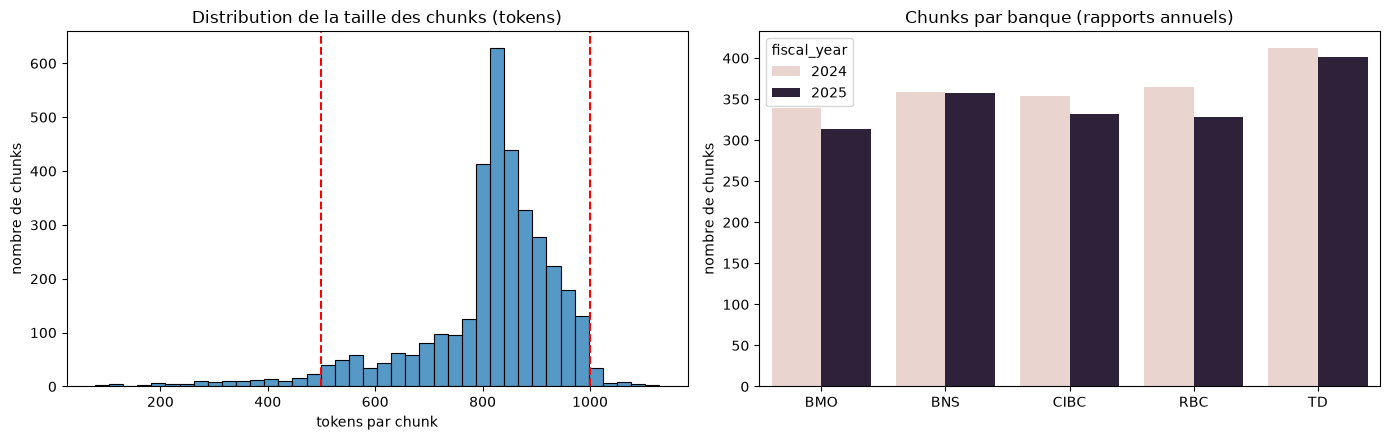

In [40]:
import matplotlib.pyplot as plt
import seaborn as sns

(ROOT / "reports" / "figures").mkdir(parents=True, exist_ok=True)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))

sns.histplot(chunk_df.n_tokens, bins=40, ax=ax[0])
for x in (500, 1000):
    ax[0].axvline(x, ls="--", c="red")
ax[0].set(title="Distribution de la taille des chunks (tokens)", xlabel="tokens par chunk", ylabel="nombre de chunks")

cnt = chunk_df.groupby(["bank_code", "fiscal_year"]).size().reset_index(name="chunks")
sns.barplot(data=cnt, x="bank_code", y="chunks", hue="fiscal_year", ax=ax[1])
ax[1].set(title="Chunks par banque (rapports annuels)", xlabel="", ylabel="nombre de chunks")

plt.tight_layout()
plt.savefig(ROOT / "reports" / "figures" / "chunk_stats.png", dpi=120)
plt.show()